<a href="https://colab.research.google.com/github/olexvysotina-cell/ML/blob/main/%22%D0%9B%D0%A05_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D1%96_%D1%80%D1%8F%D0%B4%D0%B8_%D0%92%D0%B8%D1%81%D0%BE%D1%82%D1%96%D0%BD%D0%B0_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [ ]:
# Імпортуйте необхідні бібліотеки
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [ ]:
# Завантажте датасет з Kaggle
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.


In [ ]:
# Зчитайте датасет у DataFrame та перегляньте дані
daily_climate = pd.read_csv(os.path.join(path, "kaggel_weather_2013_to_2024.csv"))

In [ ]:
daily_climate.head()

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [ ]:
daily_climate.shape

(3557, 29)

In [ ]:
daily_climate.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

In [ ]:
daily_climate.describe()

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


Підготовка даних

In [ ]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
daily_climate["DATE"] = pd.to_datetime(daily_climate["DATE"])
daily_climate = daily_climate.sort_values(by="DATE")
daily_climate = daily_climate.drop_columns["tempmax", "tempmin", "feelslikemax", "feelslikemin", "tempmax_humidity", "tempmin_humidity"]
daily_climate = daily_climate.set_index("DATE")

In [ ]:
print("Дублікатів дат:", daily_climate.index.duplicated().sum())

Дублікатів дат: 1


In [ ]:
# Перегляньте інформацію про структуру датасету
daily_climate.dtypes

,0
Unnamed: 0,int64
tempmax,float64
tempmin,float64
temp,float64
feelslikemax,float64
feelslikemin,float64
feelslike,float64
humidity,float64
precip,float64
precipprob,int64


In [ ]:
daily_climate.nunique()

,0
Unnamed: 0,3557
tempmax,313
tempmin,296
temp,306
feelslikemax,398
feelslikemin,366
feelslike,373
humidity,746
precip,489
precipprob,2


In [ ]:
# Перевірте наявність пропущених значень
daily_climate.index.isna().sum()

np.int64(0)

In [ ]:
daily_climate["year_2000"]

Графік температури

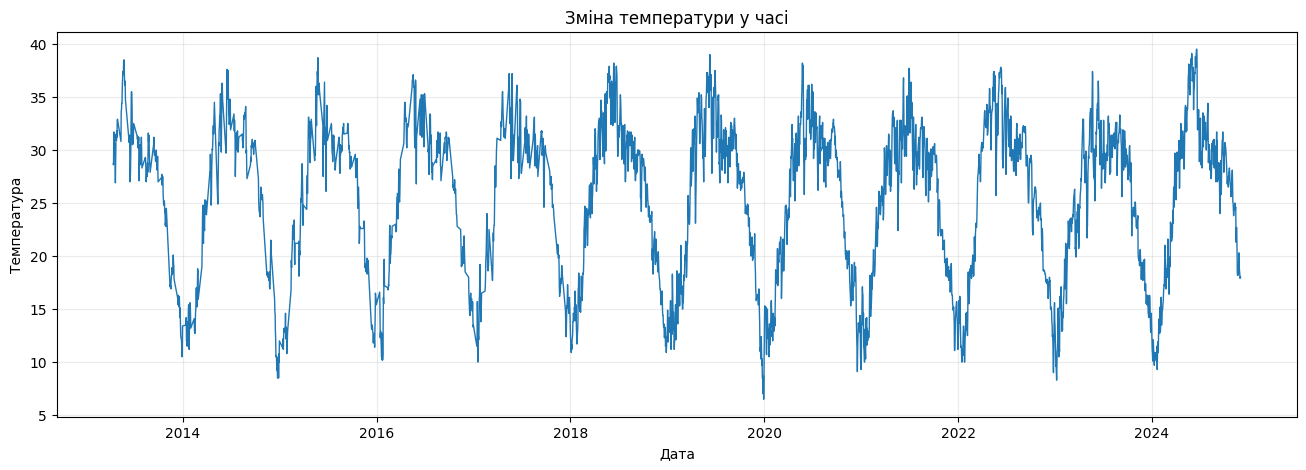

In [ ]:
# Побудуйте графік зміни температури у часі
fig, ax = plt.subplots(figsize=(16,5))
ax.plot(daily_climate.index, daily_climate["temp"], linewidth=1)
ax.set_title("Зміна температури у часі")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура")
ax.grid(alpha=0.25)
plt.show()

Ковзне середнє

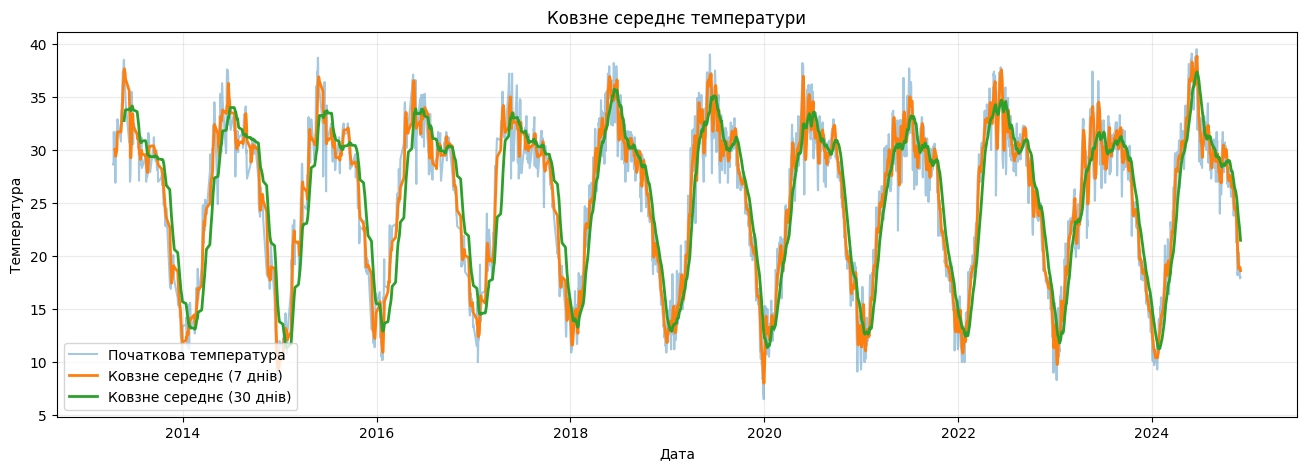

In [ ]:
# Обчисліть та візуалізуйте ковзне середнє температури
daily_climate["mean_7"] = daily_climate["temp"].rolling(window=7).mean()
daily_climate["mean_30"] = daily_climate["temp"].rolling(window=30).mean()

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(
    daily_climate.index,
    daily_climate["temp"],
    label="Початкова температура",
    alpha=0.4
)

ax.plot(
    daily_climate.index,
    daily_climate["mean_7"],
    label="Ковзне середнє (7 днів)",
    linewidth=2
)

ax.plot(
    daily_climate.index,
    daily_climate["mean_30"],
    label="Ковзне середнє (30 днів)",
    linewidth=2
)

ax.set_title("Ковзне середнє температури")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура")
ax.legend()
ax.grid(alpha=0.25)

plt.show()

Розподіл температури

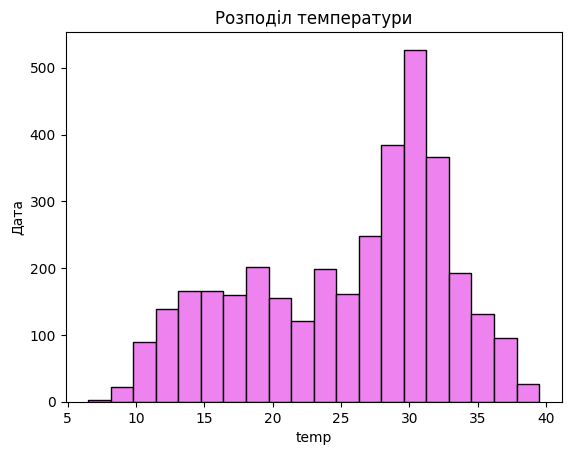

In [ ]:
# Побудуйте гістограму розподілу температури
plt.hist(daily_climate["temp"], bins=20, color="violet", edgecolor="black")
plt.xlabel("temp")
plt.ylabel("Дата")
plt.title("Розподіл температури")
plt.show()

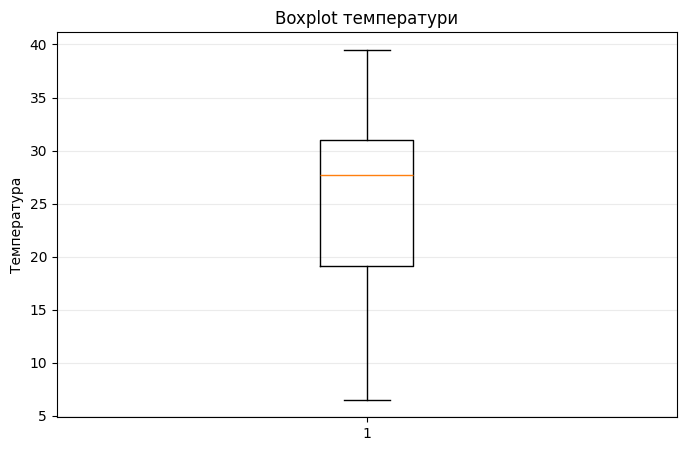

In [ ]:
# Побудуйте boxplot температури для аналізу викидів
fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(daily_climate["temp"].dropna())


ax.set_title("Boxplot температури")
ax.set_ylabel("Температура")
ax.grid(axis="y", alpha=0.25)

plt.show()

In [ ]:
Q1 = daily_climate["temp"].quantile(0.25)
Q3 = daily_climate["temp"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = daily_climate[
    (daily_climate["temp"] < lower_bound) |
    (daily_climate["temp"] > upper_bound)
]

print("Кількість потенційних викидів:", len(outliers))
print(outliers["temp"])

Кількість потенційних викидів: 0
Series([], Name: temp, dtype: float64)


Аналіз автокореляції
ACF

PACF

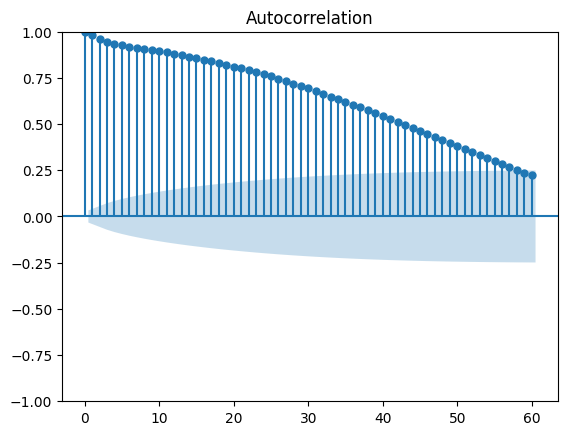

In [ ]:
# Побудуйте графік автокореляційної функції (ACF)
plot_acf(daily_climate["temp"].dropna(), lags=60)
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

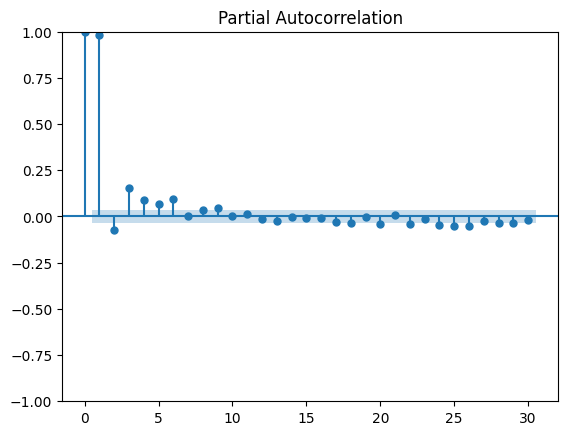

In [ ]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plot_pacf(daily_climate["temp"].dropna(), lags=30, method="ywm")
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

DATE
2013-04-14    28.7
2013-04-15    28.6
2013-04-16    31.7
2013-04-17    29.9
2013-04-18    30.6
Name: temp, dtype: float64
Кількість спостережень: 3556
Train: 2844
Test: 712
Остання дата train: 2022-12-19 00:00:00
Перша дата test: 2022-12-20 00:00:00


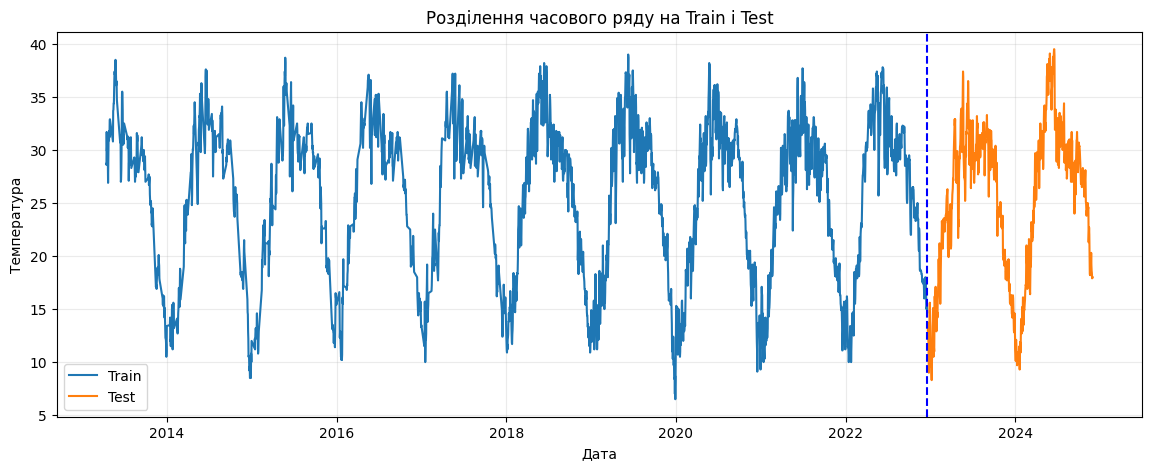

In [ ]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
climate_df = daily_climate["temp"].copy()

climate_df = climate_df.sort_index()

print(climate_df.head())
print("Кількість спостережень:", len(climate_df))

split_idx = int(len(climate_df) * 0.8)

train = climate_df.iloc[:split_idx]
test = climate_df.iloc[split_idx:]

print("Train:", len(train))
print("Test:", len(test))

print("Остання дата train:", train.index.max())
print("Перша дата test:", test.index.min())

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train.index, train, label="Train")
ax.plot(test.index, test, label="Test")
ax.axvline(
    test.index.min(),
    color="blue",
    linestyle="--",
    linewidth=1.5,
)

ax.set_title("Розділення часового ряду на Train і Test")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура")
ax.legend()
ax.grid(alpha=0.25)

plt.show()

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [ ]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
model = ARIMA(train, order=(3,1,0))
model_fit = model.fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [ ]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2845
Model:                 ARIMA(3, 1, 0)   Log Likelihood               -4993.502
Date:                Sat, 07 Nov 2026   AIC                           9995.005
Time:                        16:57:26   BIC                          10018.817
Sample:                             0   HQIC                         10003.593
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0587      0.016      3.710      0.000       0.028       0.090
ar.L2         -0.1589      0.017     -9.539      0.000      -0.192      -0.126
ar.L3         -0.1020      0.017     -6.060      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

In [ ]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки


In [ ]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA


In [ ]:
# Візуалізуйте фактичні значення та прогноз ARIMA


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [ ]:
# Підготуйте дані у форматі, необхідному для Prophet


In [ ]:
# Створіть та навчіть модель Prophet


Прогноз

In [ ]:
# Побудуйте прогноз Prophet для тестового періоду


In [ ]:
# Обчисліть MAE, RMSE, MAPE для Prophet


In [ ]:
# Візуалізуйте фактичні значення та прогноз Prophet


In [ ]:
# Побудуйте компоненти моделі Prophet


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [ ]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM


In [ ]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування


In [ ]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її


In [ ]:
# Навчіть LSTM-модель


In [ ]:
# Виведіть структуру LSTM-моделі


In [ ]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування


In [ ]:
# Сформуйте часові мітки для тестового прогнозу LSTM


In [ ]:
# Обчисліть MAE, RMSE, MAPE для LSTM


In [ ]:
# Візуалізуйте фактичні значення та прогноз LSTM


Порівняння моделей

In [ ]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.
